In [1]:

import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [2]:

iris = load_iris()

X = iris.data
y = iris.target

df = pd.DataFrame(X, columns=iris.feature_names)
df["species"] = y

print(df.head())
print("Dataset shape:", X.shape)
print("Classes:", iris.target_names)


   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   species  
0        0  
1        0  
2        0  
3        0  
4        0  
Dataset shape: (150, 4)
Classes: ['setosa' 'versicolor' 'virginica']


In [3]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 120
Testing samples: 30


In [4]:

model = LogisticRegression(max_iter=200)

model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


In [5]:

y_pred = model.predict(X_test)

print("Actual values:", y_test)
print("Predicted values:", y_pred)


Actual values: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]
Predicted values: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]


In [6]:

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy * 100, "%")
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=iris.target_names
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Accuracy: 96.66666666666667 %

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


In [7]:
flower = [[5.1, 3.5, 1.4, 0.2]]
prediction = model.predict(flower)
print("Predicted species:", iris.target_names[prediction[0]])

Predicted species: setosa


Model Accuracy: 96.67%


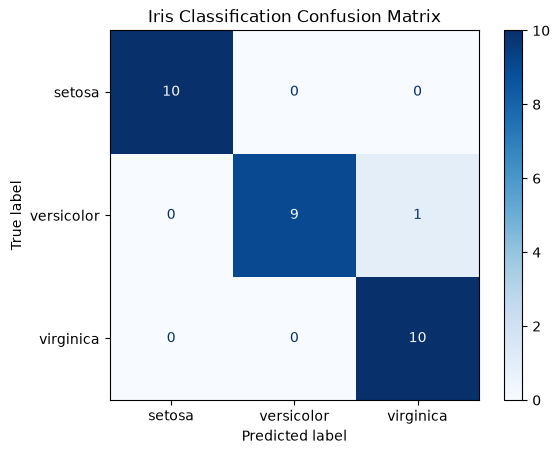

In [2]:

import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    ConfusionMatrixDisplay
)

# Step 1: Load the Iris dataset
iris = load_iris()

X = iris.data
y = iris.target

# Step 2: Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 3: Train the model
model = LogisticRegression(max_iter=200)
model.fit(X_train, y_train)

# Step 4: Make predictions
y_pred = model.predict(X_test)

# Step 5: Display accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

# Step 6: Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=iris.target_names,
    cmap="Blues"
)

plt.title("Iris Classification Confusion Matrix")
plt.show()


In [3]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import pandas as pd

models = {
    "Logistic Regression": LogisticRegression(max_iter=200),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    )
}

results = []

for name, classifier in models.items():
    classifier.fit(X_train, y_train)
    predictions = classifier.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)

    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy * 100, 2)
    })

results_df = pd.DataFrame(results)
print(results_df.sort_values(
    by="Accuracy (%)", ascending=False
))


                 Model  Accuracy (%)
2                  KNN        100.00
0  Logistic Regression         96.67
1        Decision Tree         93.33
3        Random Forest         90.00


In [4]:

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import pandas as pd

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, classifier in models.items():

    # Scale features for distance-sensitive models
    if name in ["KNN", "Logistic Regression"]:
        classifier = make_pipeline(
            StandardScaler(),
            classifier
        )

    scores = cross_val_score(
        classifier,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    cv_results.append({
        "Model": name,
        "Mean Accuracy (%)": round(scores.mean() * 100, 2),
        "Std Dev (%)": round(scores.std() * 100, 2)
    })

cv_df = pd.DataFrame(cv_results)

print(cv_df.sort_values(
    by="Mean Accuracy (%)",
    ascending=False
))



                 Model  Mean Accuracy (%)  Std Dev (%)
0  Logistic Regression              95.83         2.64
2                  KNN              95.83         2.64
1        Decision Tree              95.00         1.67
3        Random Forest              95.00         3.12


Final KNN Accuracy: 93.33333333333333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



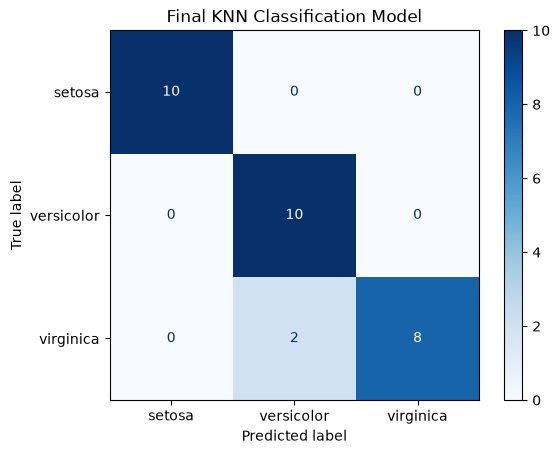

Final model saved successfully!


In [5]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import joblib

# Create the final KNN pipeline
final_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

# Train on the training data only
final_model.fit(X_train, y_train)

# Predict on the held-out test data
final_predictions = final_model.predict(X_test)

# Evaluate
print("Final KNN Accuracy:",
      accuracy_score(y_test, final_predictions) * 100)

print("\nClassification Report:")
print(classification_report(
    y_test,
    final_predictions,
    target_names=iris.target_names
))

# Visualize the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    display_labels=iris.target_names,
    cmap="Blues"
)

plt.title("Final KNN Classification Model")
plt.show()

# Save both the scaler and trained classifier
joblib.dump(final_model, "iris_knn_model.pkl")

print("Final model saved successfully!")


In [6]:
import joblib

joblib.dump(
    final_model,
    "iris_knn_model.pkl"
)

print("Model exported successfully!")

Model exported successfully!
